# Exercițiul 1: Alegerea Aleatoare a Studenților
Să presupunem că avem lista studenților din grupă care nu au prezentat încă tema, salvată într-un fișier `.csv`. Vrem să alegem aleator un număr predeterminat de studenți care vor prezenta.

Obiectivul nostru: Să extragem din listă un eșantion aleator de studenți, fără repetiție.

## Pasul 1: Citirea Datelor din Fișier
Fișierul `studenti.csv` conține câte un nume pe fiecare linie.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import arviz as az

#citim studenții din fișier(cate un nume pe linie)
studenti = np.loadtxt("studenti.csv", dtype=str, delimiter=",")

print("Studenții din listă:")
print(studenti)

Studenții din listă:
['Papadie Alexia' 'Ion Mariana' 'Maxim Mario' 'Ionescu Bianca'
 'Stan Alexandru' 'Matei Ioana' 'Neculau Cosmin' 'Marin Ana' 'Tudor Vlad'
 'Rusu Bianca' 'Contac Maria']


## Pasul 2: Alegerea Aleatoare
Folosim funcția `random.choice` din Numpy cu argumentul `replace=False`.

In [2]:
#nr. de studenti alesi
n = 3

# alegere aleatoare fara repetare
alesi = np.random.choice(studenti, size=n, replace=False)

print("Studentii alesi:")
for nume in alesi:
    print(nume)

Studentii alesi:
Maxim Mario
Stan Alexandru
Rusu Bianca


### Explicații:
- `size=n`: numărul de studenți aleși.
- `replace=False`: un student nu poate fi ales de două ori.
- Aici nu folosim seed, astfel încât la fiecare rulare să fie aleși alți studenți.

# Exercițiul 2: Jocul cu Moneda și Zarul
Doi prieteni joacă următorul joc. Primul jucător aruncă o monedă:
- Dacă pică stemă, al doilea aruncă zarul și îi dă primului o sumă egală cu $z - 3$ dolari, unde $z$ este rezultatul zarului. Jocul se încheie.
- Dacă pică ban, primul jucător îi dă celui de-al doilea 0.5 dolari și se reia pasul 1.

Obiectivul nostru: Să determinăm distribuția numărului de pași N și să estimăm suma medie S pe care al doilea jucător trebuie să i-o dea primului.

## Pasul 1: Distribuția lui N (punctul a)
N=numărul pasului la care apare prima stemă.

Ca jocul să se termine la pasul n, trebuie să avem n − 1 rezultate ban, apoi o stemă. Aruncările sunt independente, deci înmulțim probabilitățile:

$$P(N = n) = (1-p)^{n-1} \cdot p, \quad n = 1, 2, 3, \dots$$

Pentru moneda normală ($p = 0.5$):

$$P(N = n) = (0.5)^{n-1} \cdot 0.5 = \left(\frac{1}{2}\right)^n$$

Deci N are **distribuție geometrică**, cu media $E[N] = 1/p = 2$ pași.

## Pasul 2: Simularea unui Joc (punctul b)
Definim o funcție care simulează un joc și returnează cele două variabile care ne interesează:
- N: numărul de pași
- S: suma pe care al doilea jucător i-o dă primului (dacă S este negativ, de fapt primul a plătit)

In [3]:
#seed pentru reproducibilitate
np.random.seed(12)

def joc(p=0.5):
    N = 0
    S = 0

    while True:
        N += 1

        # 0 = ban, 1 = stema (stema apare cu probabilitatea p)
        moneda = np.random.choice([0, 1], p=[1 - p, p])

        if moneda == 1:
            # A aparut stema -> al doilea arunca zarul
            zar = np.random.randint(1, 7)
            S = S + (zar - 3)
            break

        else:
            #A aparut ban -> primul da celui de-al doilea 0.5$
            S = S - 0.5

    return N, S


#simulam un singur joc
N, S = joc()
print("b) Un joc: N =", N, ", S =", S)

b) Un joc: N = 2 , S = -1.5


### Explicații:
- `np.random.choice([0, 1], p=[1 - p, p])`: aruncarea monedei; stema (1) apare cu probabilitatea p.
- `np.random.randint(1, 7)`: aruncarea zarului, un număr între 1 și 6.
- La stemă, jocul se termină (`break`); la ban, se reia pasul 1.

## Pasul 3: Simularea unui Număr Mare de Jocuri (punctul c)
Jucăm 10000 de jocuri cu moneda normală ($p = 0.5$) și calculăm media lui S.

In [4]:
numar_jocuri = 10000

sume = []
for i in range(numar_jocuri):
    N, S = joc()
    sume.append(S)

print("c) Media lui S pentru p = 0.5:", np.mean(sume))

c) Media lui S pentru p = 0.5: 0.0047


## Pasul 4: Vizualizarea Distribuției lui S
Reprezentăm grafic distribuția lui S printr-o histogramă.

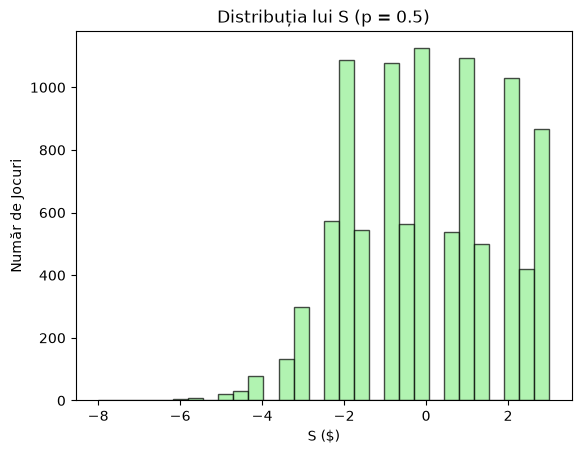

In [5]:
#afisam histograma sumelor S
plt.hist(sume, bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Distribuția lui S (p = 0.5)')
plt.xlabel('S ($)')
plt.ylabel('Număr de Jocuri')
plt.show()

### Interpretare:
- Pe axa X: suma S câștigată de primul jucător (valorile negative înseamnă că a pierdut).
- Pe axa Y: în câte jocuri a apărut fiecare valoare.
- Valorile sunt grupate în jurul lui 0.

## Pasul 5: Moneda Măsluită (punctul d)
Refacem punctul c) cu o probabilitate de apariție a stemei $p = 0.3$, respectiv $p = 0.7$.

In [6]:
#p = 0.3
sume_03 = []
for i in range(numar_jocuri):
    N, S = joc(0.3)
    sume_03.append(S)

print("d) Media lui S pentru p = 0.3:", np.mean(sume_03))

#p = 0.7
sume_07 = []
for i in range(numar_jocuri):
    N, S = joc(0.7)
    sume_07.append(S)

print("d) Media lui S pentru p = 0.7:", np.mean(sume_07))

d) Media lui S pentru p = 0.3: -0.64855
d) Media lui S pentru p = 0.7: 0.27915


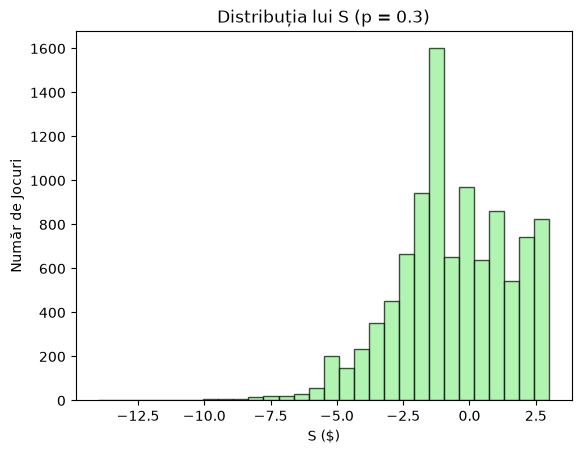

In [7]:
#afisam histograma pentru p = 0.3
plt.hist(sume_03, bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Distribuția lui S (p = 0.3)')
plt.xlabel('S ($)')
plt.ylabel('Număr de Jocuri')
plt.show()

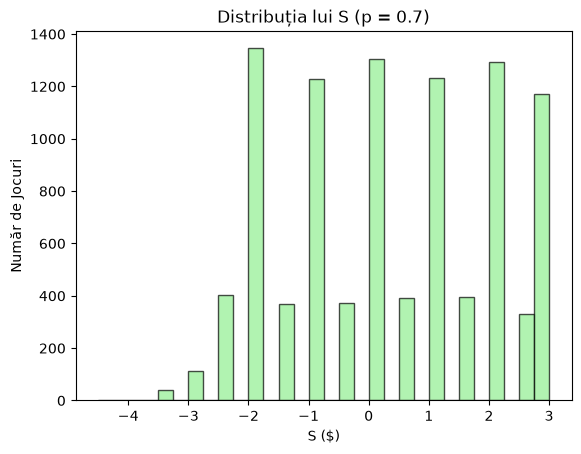

In [8]:
#afisam histograma pentru p = 0.7
plt.hist(sume_07, bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Distribuția lui S (p = 0.7)')
plt.xlabel('S ($)')
plt.ylabel('Număr de Jocuri')
plt.show()

### Interpretare:
- Pentru $p = 0.3$: stema pică rar, jocul durează mult și primul jucător plătește des 0.5 dolari. Histograma se întinde spre valori negative.
- Pentru $p = 0.7$: stema pică des, jocul se termină repede. Aproape toate valorile sunt între −2 și 3, adică practic doar rezultatul zarului.

## Media Teoretică a lui S
Media teoretică a lui S: la stemă primul primește în medie $3.5 - 3 = 0.5$, iar înainte sunt în medie $1/p - 1$ banuri, la fiecare plătind 0.5:

$$E[S] = 0.5 - 0.5 \cdot \left(\frac{1}{p} - 1\right)$$

## Rezumatul Estimărilor
Punem cele trei serii de simulări într-un obiect ArviZ, ca să putem folosi aceleași funcții ca în demo (`az.summary`, `az.plot_posterior`, `az.plot_trace`).

In [9]:
#punem rezultatele simularilor intr-un obiect ArviZ
trace = az.from_dict(posterior={
    'S_p05': np.array(sume)[None, :],
    'S_p03': np.array(sume_03)[None, :],
    'S_p07': np.array(sume_07)[None, :],
})

#rezumatul estimarilor
print("\nRezumatul estimărilor:")
summary = az.summary(trace, var_names=['S_p05', 'S_p03', 'S_p07'], kind='stats')
print(summary)


Rezumatul estimărilor:
        mean     sd  hdi_3%  hdi_97%
S_p05  0.005  1.859    -2.5      3.0
S_p03 -0.649  2.190    -4.0      3.0
S_p07  0.279  1.757    -2.0      3.0


### Interpretare:
- mean: media estimată a lui S pentru fiecare valoare a lui p.
- sd: deviația standard a lui S.
- hdi_3% și hdi_97%: intervalul în care se află cele mai probabile valori ale lui S.

## Distribuțiile lui S


Plotăm distribuțiile lui S pentru p = 0.5, p = 0.3 și p = 0.7...


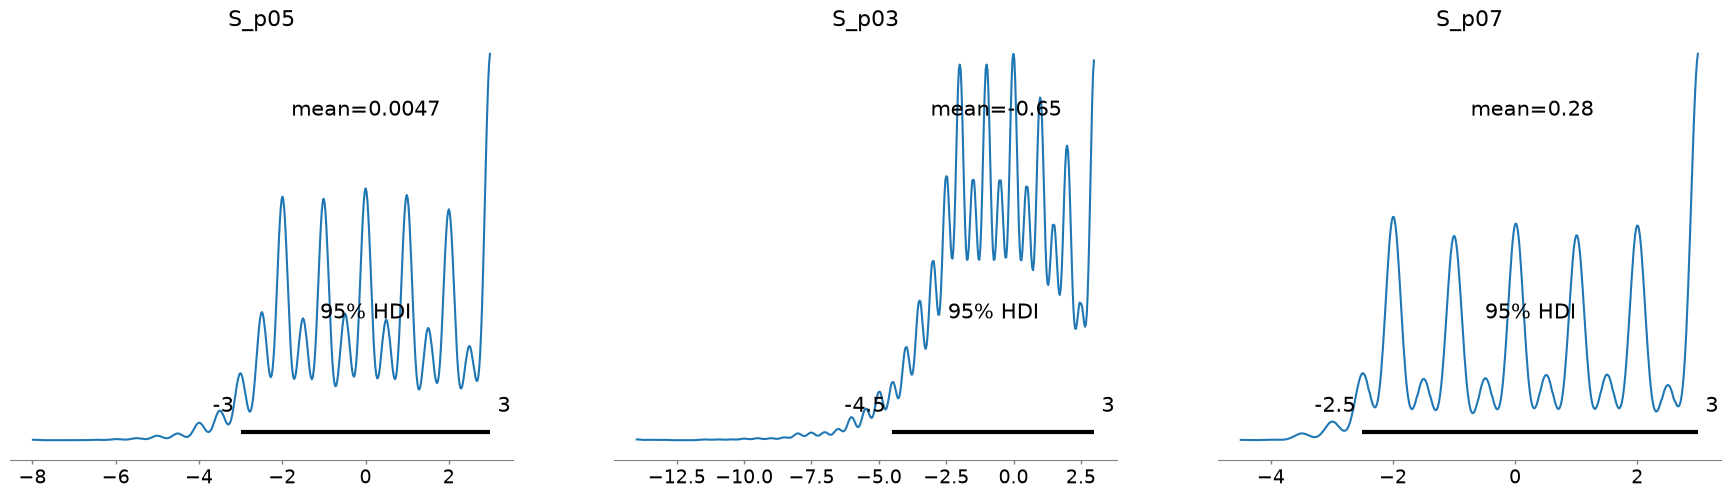

In [10]:
#afisam distributiile lui S
print("\nPlotăm distribuțiile lui S pentru p = 0.5, p = 0.3 și p = 0.7...")
az.plot_posterior(trace, var_names=['S_p05', 'S_p03', 'S_p07'], hdi_prob=0.95)
plt.show()

### Interpretare:
Graficul arată distribuția lui S pentru fiecare valoare a lui p.
- mean: media lui S, adică suma medie câștigată de primul jucător.
- 95% HDI: intervalul în care se află 95% dintre cele mai probabile valori ale lui S.

Curba are mai multe vârfuri pentru că S ia doar anumite valori (din 0.5 în 0.5), nu orice număr real.

## Traseele Simulărilor

Plotăm traseele simulărilor pentru 'S_p05', 'S_p03' și 'S_p07'...


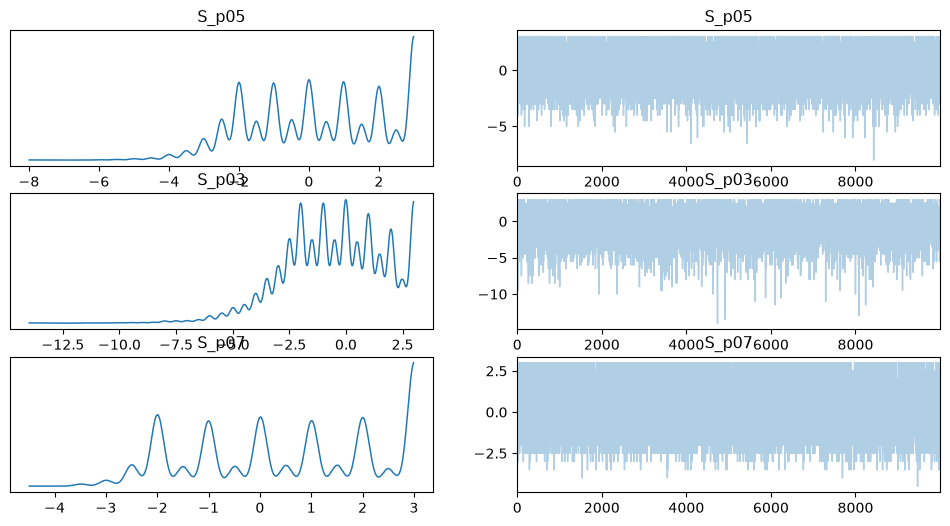

In [11]:
#plotam traseele simularilor
print("Plotăm traseele simulărilor pentru 'S_p05', 'S_p03' și 'S_p07'...")
az.plot_trace(trace, var_names=['S_p05', 'S_p03', 'S_p07'])
plt.show()

### Interpretare:
În stânga este distribuția lui S, iar în dreapta valoarea lui S la fiecare dintre cele 10000 de jocuri simulate.
Un traseu stabil, fără tendință de creștere sau scădere, arată că jocurile sunt independente și că media estimată este de încredere.

## Compararea Valorilor Estimate cu Cele Teoretice

In [12]:
#comparam valorile estimate cu valorile teoretice
for var, p in [('S_p05', 0.5), ('S_p03', 0.3), ('S_p07', 0.7)]:
    estimat = summary.loc[var, 'mean']
    teoretic = 0.5 - 0.5 * (1 / p - 1)
    print(f"\nValoarea teoretică a lui E[S] pentru p = {p}: {teoretic:.2f} $")
    print(f"Valoarea estimată a lui E[S] pentru p = {p}: {estimat:.2f} $")


Valoarea teoretică a lui E[S] pentru p = 0.5: 0.00 $
Valoarea estimată a lui E[S] pentru p = 0.5: 0.01 $

Valoarea teoretică a lui E[S] pentru p = 0.3: -0.67 $
Valoarea estimată a lui E[S] pentru p = 0.3: -0.65 $

Valoarea teoretică a lui E[S] pentru p = 0.7: 0.29 $
Valoarea estimată a lui E[S] pentru p = 0.7: 0.28 $


### Interpretare:
- Pentru $p = 0.5$: media este aproximativ 0, deci jocul este corect.
- Pentru $p = 0.3$: media este negativă, deci câștigă al doilea jucător.
- Pentru $p = 0.7$: media este pozitivă, deci câștigă primul jucător.

Diferențe mici între valorile estimate și cele teoretice indică faptul că simularea a funcționat bine.

# Exercițiul 3: Timpul de Servire într-o Frizerie
Într-o frizerie, trei frizeri își tund clienții cu vitezele medii de 3, 6, respectiv 4 clienți pe oră. Timpul de servire al unui client este modelat de distribuția exponențială.

Obiectivul nostru: Să estimăm media și deviația standard a timpului de servire X și să vizualizăm densitatea distribuției lui X.

## Pasul 1: Parametrii Modelului
- Parametrii distribuțiilor exponențiale: $\lambda_1 = 3$, $\lambda_2 = 6$, $\lambda_3 = 4$ (clienți pe oră)
- Probabilitățile de preluare: $3/13$, $6/13$, $4/13$

Probabilitățile sunt proporționale cu vitezele frizerilor: împreună servesc $3 + 6 + 4 = 13$ clienți pe oră, iar fiecare preia o parte egală cu viteza lui.

Vom genera 10000 de valori pentru X.

In [13]:
#seed pentru reproducibilitate
np.random.seed(12)

#parametrii modelului
lambdas = [3, 6, 4]                  #clienti pe ora
prob = [3/13, 6/13, 4/13]            #probabilitatea de preluare de catre fiecare frizer

#generam timpii de servire
X = []
for i in range(10000):
    #alegem frizerul: 0 = primul, 1 = al doilea, 2 = al treilea
    frizer = np.random.choice([0, 1, 2], p=prob)

    #timpul de servire: Exp(lambda), cu scale = 1/lambda (în ore)
    timp = np.random.exponential(scale=1 / lambdas[frizer])
    X.append(timp)

X = np.array(X)

### Explicații:
- Pentru fiecare client alegem întâi frizerul, cu probabilitățile date.
- Apoi generăm timpul de servire din distribuția exponențială a frizerului ales.
- `np.random.exponential(scale=1/λ)`: în Numpy, parametrul este $1/\lambda$, adică timpul mediu de servire.

## Pasul 2: Estimarea Mediei și a Deviației Standard

In [14]:
media = np.mean(X)
deviatia = np.std(X)

print(f"Media lui X: {media:.4f} ore (~{media * 60:.1f} minute)")
print(f"Deviația standard a lui X: {deviatia:.4f} ore (~{deviatia * 60:.1f} minute)")

Media lui X: 0.2316 ore (~13.9 minute)
Deviația standard a lui X: 0.2450 ore (~14.7 minute)


## Pasul 3: Vizualizarea Densității lui X
Deoarece X este o variabilă continuă, densitatea aproximativă se poate vizualiza folosind funcția `plot_kde` din ArviZ.

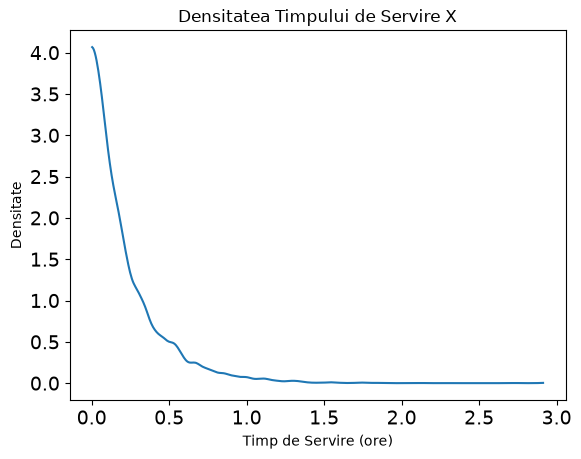

In [15]:
#afisam densitatea aproximativa a lui X
az.plot_kde(X)
plt.title('Densitatea Timpului de Servire X')
plt.xlabel('Timp de Servire (ore)')
plt.ylabel('Densitate')
plt.show()

### Interpretare:
Densitatea este mare lângă 0 și scade rapid, ca la o distribuție exponențială: majoritatea clienților sunt serviți repede, iar timpii lungi sunt rari.

## Rezumatul Estimărilor

In [16]:
#punem valorile lui X într-un obiect ArviZ
trace_X = az.from_dict(posterior={'X': X[None, :]})

#rezumatul estimarilor
print("\nRezumatul estimărilor:")
summary_X = az.summary(trace_X, var_names=['X'], kind='stats')
print(summary_X)


Rezumatul estimărilor:
    mean     sd  hdi_3%  hdi_97%
X  0.232  0.245     0.0    0.676


## Distribuția lui X


Plotăm distribuția lui X...


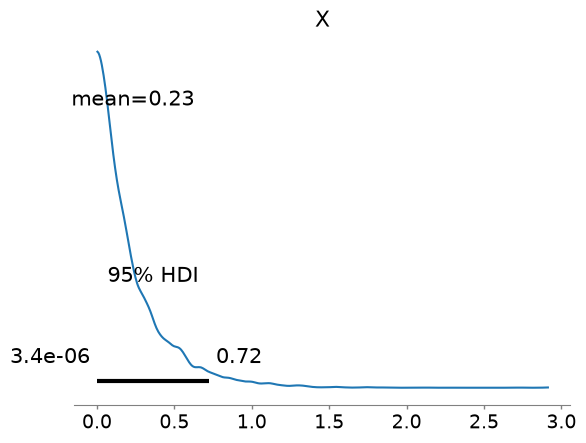

In [17]:
#afisam distributia lui X
print("\nPlotăm distribuția lui X...")
az.plot_posterior(trace_X, var_names=['X'], hdi_prob=0.95)
plt.show()

### Interpretare:
- mean: timpul mediu de servire (în ore).
- 95% HDI: intervalul în care se află 95% dintre cei mai probabili timpi de servire.

## Compararea Valorilor Estimate cu Cele Teoretice
$$E[X] = \frac{3}{13}\cdot\frac{1}{3} + \frac{6}{13}\cdot\frac{1}{6} + \frac{4}{13}\cdot\frac{1}{4} = \frac{3}{13} \text{ ore}$$

In [18]:
#comparam media estimata cu media teoretica
media_teoretica = 3/13 * 1/3 + 6/13 * 1/6 + 4/13 * 1/4
print(f"Valoarea teoretică a mediei: {media_teoretica:.4f} ore (~{media_teoretica * 60:.1f} minute)")
print(f"Valoarea estimată a mediei: {media:.4f} ore (~{media * 60:.1f} minute)")

Valoarea teoretică a mediei: 0.2308 ore (~13.8 minute)
Valoarea estimată a mediei: 0.2316 ore (~13.9 minute)


### Interpretare:
Observăm cât de aproape este media estimată de valoarea teoretică. Diferențele mici indică faptul că simularea a funcționat bine.